## 1. Đọc dữ liệu
Đọc dữ liệu Wine và bỏ cột cuối theo yêu cầu của file gốc.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

file = Path("D00 - wine.data.xlsx")
if file.exists():
    df = pd.read_excel(file, sheet_name="wine.data")
    df.columns = ["class", "alcohol", "malic_acid", "ash", "alcalinity_of_ash",
                  "magnesium", "total_phenols", "flavanoids", "nonflavanoid_phenols",
                  "proanthocyanins", "color_intensity", "hue", "od280_od315", "proline"]
    df = df.drop(columns="proline")
    print("Nguồn: D00 - wine.data.xlsx (sheet wine.data)")
else:
    # Dữ liệu Wine chuẩn tương ứng khi file Excel chưa được tải lên.
    wine = load_wine()
    df = pd.DataFrame(wine.data, columns=wine.feature_names)
    df["class"] = wine.target + 1
    df = df.rename(columns={"od280/od315_of_diluted_wines": "od280_od315"})
    df = df.drop(columns="proline")
    print("Không tìm thấy Excel; dùng bản Wine tích hợp và bỏ Proline.")

TARGET = "class"
FEATURES = [c for c in df.columns if c != TARGET]
print("Kích thước:", df.shape, "| Số đặc trưng:", len(FEATURES))
display(df.head())

Nguồn: D00 - wine.data.xlsx (sheet wine.data)
Kích thước: (178, 13) | Số đặc trưng: 12


,class,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93


## 2. EDA – Khám phá dữ liệu
Kiểm tra kích thước, giá trị thiếu, dữ liệu trùng và phân bố các lớp.

In [2]:
print("Kích thước:", df.shape)
print("Số giá trị thiếu:", int(df.isna().sum().sum()))
print("Số dòng trùng:", int(df.duplicated().sum()))
print("Kiểu dữ liệu:")
display(df.dtypes.to_frame("Kiểu"))
print("Thống kê mô tả:")
display(df.describe().T[["min", "max", "mean", "std"]])
print("Số mẫu theo lớp:")
display(df[TARGET].value_counts().sort_index().to_frame("Số mẫu"))

Kích thước: (178, 13)
Số giá trị thiếu: 0
Số dòng trùng: 0
Kiểu dữ liệu:


,Kiểu
class,int64
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,int64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64


Thống kê mô tả:


,min,max,mean,std
class,1.00,3.00,1.938202,0.775035
alcohol,11.03,14.83,13.000618,0.811827
malic_acid,0.74,5.80,2.336348,1.117146
ash,1.36,3.23,2.366517,0.274344
alcalinity_of_ash,10.60,30.00,19.494944,3.339564
magnesium,70.00,162.00,99.741573,14.282484
total_phenols,0.98,3.88,2.295112,0.625851
flavanoids,0.34,5.08,2.029270,0.998859
nonflavanoid_phenols,0.13,0.66,0.361854,0.124453
proanthocyanins,0.41,3.58,1.590899,0.572359


Số mẫu theo lớp:


,Số mẫu
class,
1,59
2,71
3,48


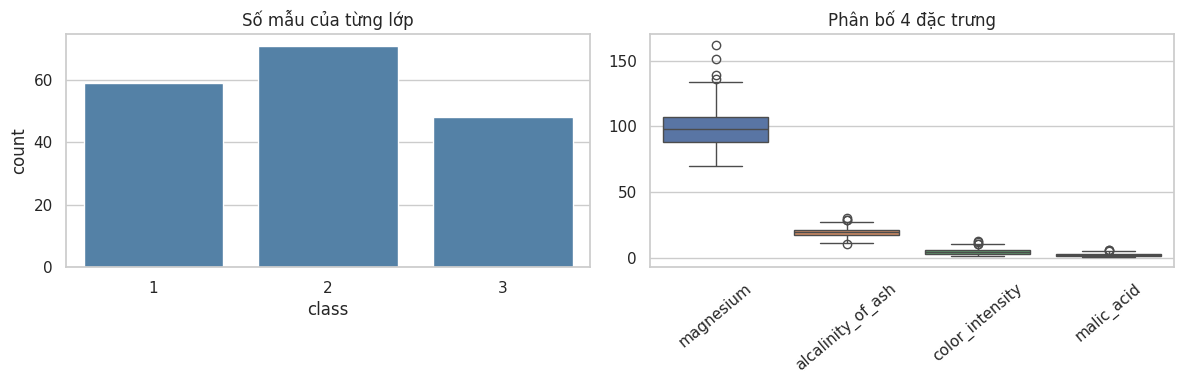

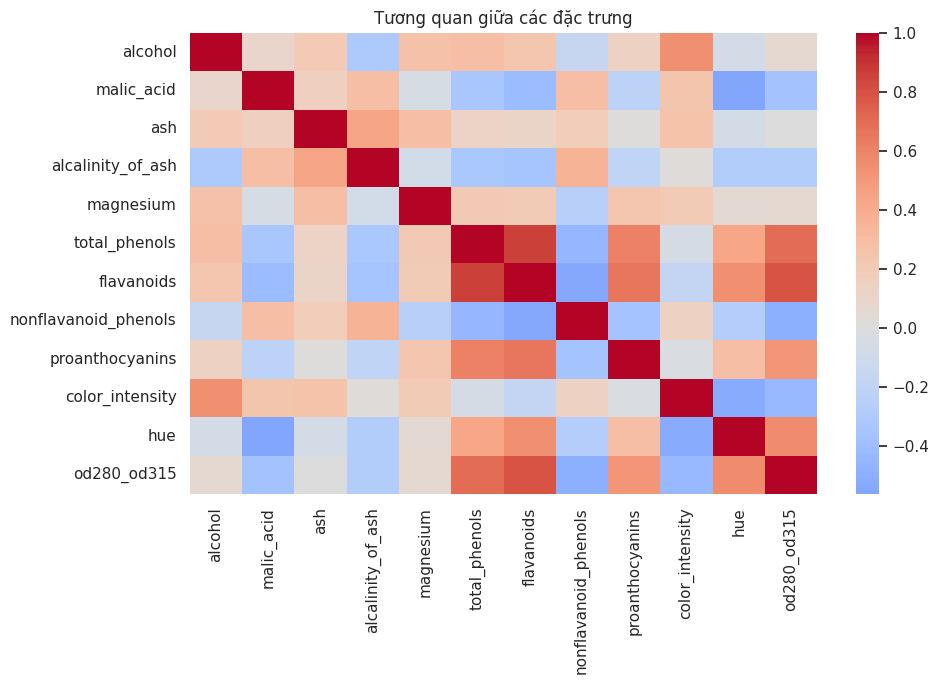

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x=TARGET, ax=axes[0], color="steelblue")
axes[0].set_title("Số mẫu của từng lớp")
top4 = df[FEATURES].apply(pd.to_numeric, errors="coerce").std().nlargest(4).index
sns.boxplot(data=df[top4], ax=axes[1])
axes[1].tick_params(axis="x", rotation=40)
axes[1].set_title("Phân bố 4 đặc trưng")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df[FEATURES].corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Tương quan giữa các đặc trưng")
plt.tight_layout()
plt.show()

## 3. Cleaning – Làm sạch dữ liệu
Xóa dòng trùng, bỏ dòng thiếu nhãn. Giá trị thiếu ở đặc trưng sẽ được điền bằng trung vị.

In [4]:
before = len(df)
df = df.drop_duplicates().copy()
for col in FEATURES:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = df[TARGET].astype(int)
print("Số dòng đã loại:", before - len(df))
print("Số giá trị thiếu ở đặc trưng:", int(df[FEATURES].isna().sum().sum()))
print("Kích thước sau cleaning:", df.shape)

Số dòng đã loại: 0
Số giá trị thiếu ở đặc trưng: 0
Kích thước sau cleaning: (178, 13)


## 4. Feature Engineering – Chuẩn bị dữ liệu
Tách đặc trưng và nhãn, chia train/test (80/20). Chuẩn hóa giúp KNN đo khoảng cách công bằng hơn.

In [5]:
X = df[FEATURES]
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
model = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier())
])
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (142, 12) | Test: (36, 12)


## 5. Huấn luyện KNN (10-fold CV)
Thử nhiều giá trị K và chọn mô hình có F1-macro trung bình cao nhất.

In [6]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(
    model,
    param_grid={
        "knn__n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15],
        "knn__weights": ["uniform", "distance"],
        "knn__p": [2]  # Khoảng cách Euclidean
    },
    scoring="f1_macro", cv=cv, n_jobs=-1
)
search.fit(X_train, y_train)
best_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_)
print("Tham số tốt nhất:", search.best_params_)
print("F1-macro 10-fold CV:", round(search.best_score_, 4))
display(results.sort_values("rank_test_score")[
    ["param_knn__n_neighbors", "param_knn__weights", "mean_test_score"]
].head(8).rename(columns={"mean_test_score": "F1-macro"}))

Tham số tốt nhất: {'knn__n_neighbors': 15, 'knn__p': 2, 'knn__weights': 'uniform'}
F1-macro 10-fold CV: 0.9482


,param_knn__n_neighbors,param_knn__weights,F1-macro
14,15,uniform,0.948182
5,5,distance,0.947661
4,5,uniform,0.947661
3,3,distance,0.947508
15,15,distance,0.947508
2,3,uniform,0.947508
0,1,uniform,0.946347
1,1,distance,0.946347


## 6. Đánh giá mô hình
Đánh giá trên tập test bằng Accuracy, Precision, Recall, F1-score và ma trận nhầm lẫn.

,Mô hình,K tốt nhất,Accuracy,Precision,Recall,F1-score,F1 CV (10-fold)
0,KNN,15,0.9167,0.9333,0.9286,0.923,0.9482


              precision    recall  f1-score   support

           1       0.80      1.00      0.89        12
           2       1.00      0.79      0.88        14
           3       1.00      1.00      1.00        10

    accuracy                           0.92        36
   macro avg       0.93      0.93      0.92        36
weighted avg       0.93      0.92      0.92        36



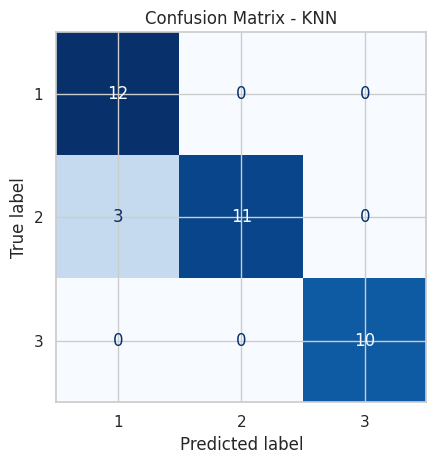

In [7]:
y_pred = best_model.predict(X_test)
metrics = pd.DataFrame([{
    "Mô hình": "KNN",
    "K tốt nhất": search.best_params_["knn__n_neighbors"],
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-score": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "F1 CV (10-fold)": search.best_score_
}])
display(metrics.round(4))
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - KNN")
plt.tight_layout()
plt.show()

## 7. Trực quan kết quả
Biểu đồ cho biết F1-score thay đổi khi tăng số láng giềng K.

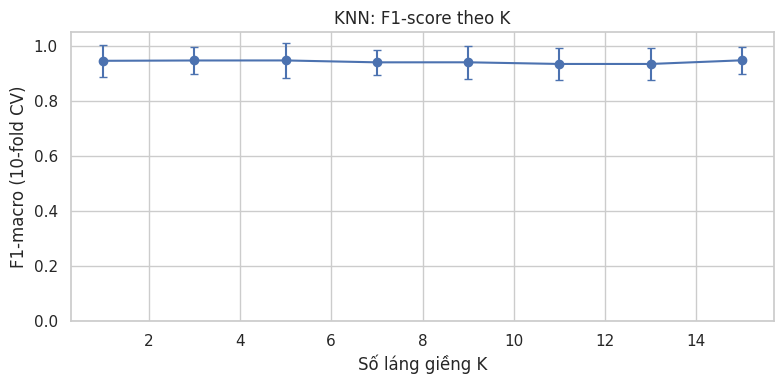

In [8]:
scores = results[results["param_knn__weights"] == search.best_params_["knn__weights"]].copy()
scores = scores.sort_values("param_knn__n_neighbors")
plt.figure(figsize=(8, 4))
plt.errorbar(scores["param_knn__n_neighbors"].astype(int), scores["mean_test_score"],
             yerr=scores["std_test_score"], marker="o", capsize=3)
plt.xlabel("Số láng giềng K")
plt.ylabel("F1-macro (10-fold CV)")
plt.title("KNN: F1-score theo K")
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

## 8. Kết luận
KNN được đánh giá bằng 10-fold cross-validation và tập test. Dựa vào bảng kết quả để nhận xét độ chính xác của mô hình.